# Step 3: News headlines and FinBERT sentiment

## 3.1 Load the news file


In [8]:
%pip install torch torchvision torchaudio
%pip install transformers


Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 4.6 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 4.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.2/807.2 kB 7.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [transformers] [transformers]]
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import re
import numpy as np
import pandas as pd

NEWS_CSV = "data/Combined_News_DJIA.csv"
assert os.path.exists(NEWS_CSV), f"Put the Kaggle file at {NEWS_CSV}"

news = pd.read_csv(NEWS_CSV)
news["Date"] = pd.to_datetime(news["Date"])
news = news.sort_values("Date").reset_index(drop=True)
print(news.shape, news["Date"].min().date(), "to", news["Date"].max().date())
news.iloc[:3, :5]

(1989, 27) 2008-08-08 to 2016-07-01


,Date,Label,Top1,Top2,Top3
0,2008-08-08,0,"b""Georgia 'downs two Russian warplanes' as cou...",b'BREAKING: Musharraf to be impeached.',b'Russia Today: Columns of troops roll into So...
1,2008-08-11,1,b'Why wont America and Nato help us? If they w...,b'Bush puts foot down on Georgian conflict',"b""Jewish Georgian minister: Thanks to Israeli ..."
2,2008-08-12,0,b'Remember that adorable 9-year-old who sang a...,"b""Russia 'ends Georgia operation'""","b'""If we had no sexual harassment we would hav..."


## 3.2 Restrict to the price date range

Use the same dates as your price data, so every news day can be matched to a trading day.

In [4]:
prices = pd.read_csv("data/sp500_raw.csv", parse_dates=["Date"])
START, END = prices["Date"].min(), prices["Date"].max()

news = news[(news["Date"] >= START) & (news["Date"] <= END)].reset_index(drop=True)
print("news days in range:", len(news), "|", news["Date"].min().date(), "to", news["Date"].max().date())

news days in range: 1989 | 2008-08-08 to 2016-07-01


## 3.3 Reshape to one headline per row

The file has 25 headline columns per day. FinBERT scores one headline at a time,
so this turns the wide table into a long one: `Date`, `headline`.

In [5]:
top_cols = [c for c in news.columns if c.startswith("Top")]
print("headline columns:", len(top_cols))

long = news.melt(id_vars="Date", value_vars=top_cols, value_name="headline").dropna(subset=["headline"])
long = long.drop(columns="variable")
print("raw headlines:", len(long))
long.head()

headline columns: 25
raw headlines: 49718


,Date,headline
0,2008-08-08,"b""Georgia 'downs two Russian warplanes' as cou..."
1,2008-08-11,b'Why wont America and Nato help us? If they w...
2,2008-08-12,b'Remember that adorable 9-year-old who sang a...
3,2008-08-13,b' U.S. refuses Israel weapons to attack Iran:...
4,2008-08-14,b'All the experts admit that we should legalis...


## 3.4 Clean the text

Many headlines in this file are stored as Python byte strings, like `b"Georgia 'downs two Russian warplanes'"`.
This strips the leading `b'` or `b"` and the closing quote, removes extra spaces, and drops very short or duplicate headlines.

In [6]:
def clean(text):
    t = str(text).strip()
    t = re.sub(r"^b['\"]", "", t)
    t = t.strip().strip("'\"").strip()
    t = re.sub(r"\s+", " ", t)
    return t

before = long["headline"].iloc[:3].tolist()
long["headline"] = long["headline"].map(clean)
print("before:", before)
print("after: ", long["headline"].iloc[:3].tolist())

long = long[long["headline"].str.len() > 5]
long = long.drop_duplicates(["Date", "headline"]).sort_values(["Date", "headline"]).reset_index(drop=True)
print("\nheadlines after cleaning:", len(long))
print("average per day:", round(len(long) / long["Date"].nunique(), 1))

before: ['b"Georgia \'downs two Russian warplanes\' as countries move to brink of war"', "b'Why wont America and Nato help us? If they wont help us now, why did we help them in Iraq?'", "b'Remember that adorable 9-year-old who sang at the opening ceremonies? That was fake, too.'"]
after:  ["Georgia 'downs two Russian warplanes' as countries move to brink of war", 'Why wont America and Nato help us? If they wont help us now, why did we help them in Iraq?', 'Remember that adorable 9-year-old who sang at the opening ceremonies? That was fake, too.']

headlines after cleaning: 49700
average per day: 25.0


## 3.5 Load FinBERT and test it on three sentences

Expected: the first is positive, the second negative, the third neutral.
This is the cell that downloads the model the first time, so it can take a few minutes.

In [9]:
import torch
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1
print("running on:", "GPU" if device == 0 else "CPU")

finbert = pipeline("text-classification", model="ProsusAI/finbert", top_k=None,
                   truncation=True, max_length=64, device=device)

def score_headlines(texts, batch_size=64):
    # returns a DataFrame with columns positive, negative, neutral (probabilities that sum to 1)
    out = finbert(list(texts), batch_size=batch_size)
    return pd.DataFrame([{d["label"].lower(): d["score"] for d in o} for o in out])[["positive", "negative", "neutral"]]

score_headlines([
    "Company profits jump after record quarter",
    "Bank shares plunge as losses mount",
    "The central bank will meet on Tuesday",
]).round(3)

/home/kundan/Stock_Prediction/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


running on: GPU


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 2825.91it/s]


,positive,negative,neutral
0,0.566,0.374,0.061
1,0.014,0.938,0.048
2,0.034,0.058,0.908


## 3.6 Score all headlines (slow)

Roughly 50,000 headlines. On a CPU this can take 20 to 60 minutes, on a GPU a few minutes.
Progress is saved to `data/headline_scores.csv` after every chunk, so if it stops you can run the cell again and it continues where it left off.

To test quickly first, set `SAMPLE = 500`. Set it back to `None` for the full run and delete `data/headline_scores.csv` before that.
Tip: you can run this notebook in Google Colab with a GPU and copy the CSV files back.

In [10]:
from tqdm.auto import tqdm

SAMPLE = None          # e.g. 500 for a quick test
CHUNK = 1000
SCORES_CSV = "data/headline_scores.csv"

todo = long if SAMPLE is None else long.head(SAMPLE)

if os.path.exists(SCORES_CSV):
    done = pd.read_csv(SCORES_CSV, parse_dates=["Date"])
else:
    done = pd.DataFrame(columns=["Date", "headline", "positive", "negative", "neutral"])
done["Date"] = pd.to_datetime(done["Date"])
print("already scored:", len(done), "of", len(todo))

key = lambda d: d["Date"].dt.strftime("%Y-%m-%d") + "|" + d["headline"]
remaining = todo[~key(todo).isin(set(key(done)))].reset_index(drop=True)
print("still to score:", len(remaining))

for i in tqdm(range(0, len(remaining), CHUNK)):
    part = remaining.iloc[i:i + CHUNK].reset_index(drop=True)
    scored = pd.concat([part, score_headlines(part["headline"])], axis=1)
    done = pd.concat([done, scored], ignore_index=True)
    done.to_csv(SCORES_CSV, index=False)

done["Date"] = pd.to_datetime(done["Date"])
done[["positive", "negative", "neutral"]] = done[["positive", "negative", "neutral"]].astype(float)
print("total scored:", len(done))
done.head()

already scored: 0 of 49700
still to score: 49700


100%|██████████| 50/50 [04:11<00:00,  5.03s/it]

total scored: 49700


,Date,headline,positive,negative,neutral
0,2008-08-08,150 Russian tanks have entered South Ossetia w...,0.023724,0.883901,0.092375
1,2008-08-08,"Afghan children raped with 'impunity,' U.N. of...",0.016674,0.868590,0.114736
2,2008-08-08,Al-Qaeda Faces Islamist Backlash,0.045611,0.498769,0.455621
3,2008-08-08,Announcing:Class Action Lawsuit on Behalf of A...,0.031936,0.524746,0.443317
4,2008-08-08,BREAKING: Musharraf to be impeached.,0.020223,0.685217,0.294561


## 3.7 Check the scores

The three scores add up to 1 for every headline. On world news most headlines come out neutral or negative,
which is normal for this dataset.

In [11]:
sums = done[["positive", "negative", "neutral"]].sum(axis=1)
print("scores sum to 1:", bool(np.allclose(sums, 1, atol=1e-3)))

label = done[["positive", "negative", "neutral"]].idxmax(axis=1)
print("\nshare of headlines by top label:")
print(label.value_counts(normalize=True).round(3).to_string())

print("\nmost positive headlines:")
for t in done.nlargest(3, "positive")["headline"]:
    print(" +", t[:100])
print("\nmost negative headlines:")
for t in done.nlargest(3, "negative")["headline"]:
    print(" -", t[:100])

scores sum to 1: True

share of headlines by top label:
negative    0.503
neutral     0.439
positive    0.059

most positive headlines:
 + Afghan life expectancy has improved by 18 years since 2001
 + China says its economy expanded by 8.7% in 2009, exceeding even the government's own initial expecta
 + A test-run of issuing free heroin to addicts in Copenhagen appears to be successful, with initial re

most negative headlines:
 - China economy grows 6.9 percent in Q3, weakest since 2009
 - Russian vodka exports slump 40% because of sanctions
 - Norway wealth fund drops 29.4bn amid market rout. The worlds largest sovereign wealth fund, which is


## 3.8 Aggregate to one row per day

The model needs one set of numbers per day, so average the scores over that day's headlines.
`n_headlines` is kept for reference.

In [12]:
daily = (done.groupby("Date")
             .agg(sent_pos=("positive", "mean"),
                  sent_neg=("negative", "mean"),
                  sent_neu=("neutral", "mean"),
                  n_headlines=("positive", "size"))
             .reset_index())

print(daily.shape, daily["Date"].min().date(), "to", daily["Date"].max().date())
daily.describe().round(3)

(1989, 5) 2008-08-08 to 2016-07-01


,Date,sent_pos,sent_neg,sent_neu,n_headlines
count,1989,1989.000,1989.000,1989.000,1989.000
mean,2012-07-20 11:52:23.891402,0.101,0.461,0.438,24.987
min,2008-08-08 00:00:00,0.027,0.196,0.208,22.000
25%,2010-07-30 00:00:00,0.072,0.407,0.387,25.000
50%,2012-07-19 00:00:00,0.095,0.461,0.439,25.000
75%,2014-07-14 00:00:00,0.124,0.514,0.485,25.000
max,2016-07-01 00:00:00,0.318,0.746,0.685,25.000
std,NaN,0.039,0.078,0.071,0.132


## 3.9 Plot sentiment over time

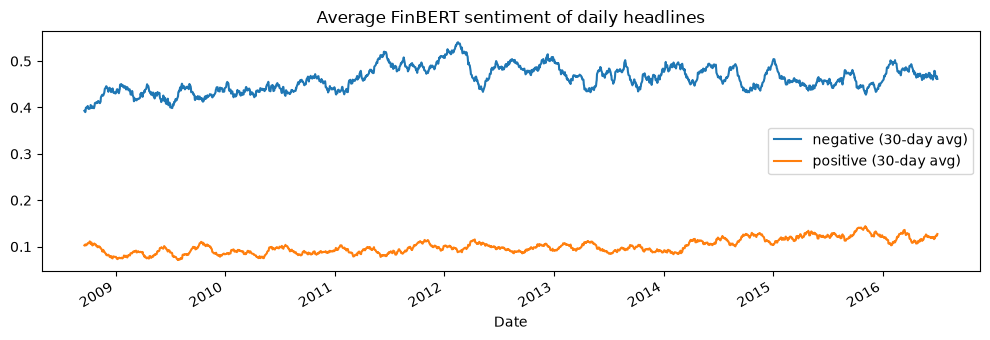

In [13]:
import matplotlib.pyplot as plt

d = daily.set_index("Date")
fig, ax = plt.subplots(figsize=(10, 3.5))
d["sent_neg"].rolling(30).mean().plot(ax=ax, label="negative (30-day avg)")
d["sent_pos"].rolling(30).mean().plot(ax=ax, label="positive (30-day avg)")
ax.set_title("Average FinBERT sentiment of daily headlines")
ax.legend()
plt.tight_layout()
plt.show()

## 3.10 Save

In [15]:
daily.to_csv("data/sentiment_daily.csv", index=False)
print("saved data/sentiment_daily.csv with", len(daily), "rows")

saved data/sentiment_daily.csv with 1989 rows


**Done with step 3 when** `data/sentiment_daily.csv` exists with about 1,900 to 2,000 rows (set `SAMPLE = None` for the full run).
Next: step 4, join sentiment with the technical features, lag it by one day, and split by time.